In [41]:

# 1. Data manipulation
import numpy as np
import pandas as pd

# 2. Data visualization
import seaborn as sns
import matplotlib.pyplot as plt

# 3. Warnings
import warnings
warnings.filterwarnings('ignore')

# 4. Data preprocessing
from sklearn.preprocessing import LabelEncoder, StandardScaler

# 5. Train-test split
from sklearn.model_selection import train_test_split

# 6. Traditional Machine Learning model
from sklearn.linear_model import Perceptron

# 7. Model evaluation
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# 8. Deep Learning - CNN
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Dense,
    Conv2D,
    Flatten,
    MaxPooling2D,
    Dropout
)

# 9. MNIST handwritten digit dataset
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical



In [42]:
df = pd.read_csv("train/train.csv")
df_test=pd.read_csv("test/test.csv")

In [43]:
df.head()


,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [44]:
df.shape


(42000, 785)

In [45]:
df.isnull().sum()

label       0
pixel0      0
pixel1      0
pixel2      0
pixel3      0
           ..
pixel779    0
pixel780    0
pixel781    0
pixel782    0
pixel783    0
Length: 785, dtype: int64

In [46]:
print(df.columns.tolist())

['label', 'pixel0', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5', 'pixel6', 'pixel7', 'pixel8', 'pixel9', 'pixel10', 'pixel11', 'pixel12', 'pixel13', 'pixel14', 'pixel15', 'pixel16', 'pixel17', 'pixel18', 'pixel19', 'pixel20', 'pixel21', 'pixel22', 'pixel23', 'pixel24', 'pixel25', 'pixel26', 'pixel27', 'pixel28', 'pixel29', 'pixel30', 'pixel31', 'pixel32', 'pixel33', 'pixel34', 'pixel35', 'pixel36', 'pixel37', 'pixel38', 'pixel39', 'pixel40', 'pixel41', 'pixel42', 'pixel43', 'pixel44', 'pixel45', 'pixel46', 'pixel47', 'pixel48', 'pixel49', 'pixel50', 'pixel51', 'pixel52', 'pixel53', 'pixel54', 'pixel55', 'pixel56', 'pixel57', 'pixel58', 'pixel59', 'pixel60', 'pixel61', 'pixel62', 'pixel63', 'pixel64', 'pixel65', 'pixel66', 'pixel67', 'pixel68', 'pixel69', 'pixel70', 'pixel71', 'pixel72', 'pixel73', 'pixel74', 'pixel75', 'pixel76', 'pixel77', 'pixel78', 'pixel79', 'pixel80', 'pixel81', 'pixel82', 'pixel83', 'pixel84', 'pixel85', 'pixel86', 'pixel87', 'pixel88', 'pixel89', 'pixel90',

In [47]:
print("Training columns:", df.columns.tolist()[:10])
print("Test columns:", df_test.columns.tolist()[:10])

print("Training shape:", df.shape)
print("Test shape:", df_test.shape)


Training columns: ['label', 'pixel0', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5', 'pixel6', 'pixel7', 'pixel8']
Test columns: ['pixel0', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5', 'pixel6', 'pixel7', 'pixel8', 'pixel9']
Training shape: (42000, 785)
Test shape: (28000, 784)


In [48]:
# Separate training features and labels
X = df.drop("label", axis=1).values
y = df["label"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Normalize pixel values
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Reshape for CNN
X_train_img = X_train.reshape(-1, 28, 28)
X_test_img = X_test.reshape(-1, 28, 28)

In [49]:
X_train_img

array([[[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       ...,

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0.

In [50]:
y_train_cat = to_categorical(y_train,10)
y_test_cat = to_categorical(y_test,10)

In [51]:
perceptron = Sequential([
    Flatten(input_shape=(28,28)),
    Dense(10,activation="softmax")
])

In [52]:
perceptron.compile(optimizer="sgd",loss="categorical_crossentropy",metrics=["accuracy"])

In [53]:
history_percp = perceptron.fit(X_train_img , y_train_cat , epochs=5 , batch_size=32 , validation_data=(X_test_img , y_test_cat),verbose=1)

Epoch 1/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.7792 - loss: 0.9563 - val_accuracy: 0.8527 - val_loss: 0.6017
Epoch 2/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8703 - loss: 0.5296 - val_accuracy: 0.8730 - val_loss: 0.4836
Epoch 3/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8830 - loss: 0.4537 - val_accuracy: 0.8815 - val_loss: 0.4358
Epoch 4/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8897 - loss: 0.4165 - val_accuracy: 0.8870 - val_loss: 0.4087
Epoch 5/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8943 - loss: 0.3934 - val_accuracy: 0.8914 - val_loss: 0.3907


In [54]:
acc_percp = perceptron.evaluate(X_test_img , y_test_cat,verbose=0)[1]

In [55]:
acc_percp

0.8914285898208618

In [56]:
#ANN
ann=Sequential([
    Flatten(input_shape=(28,28)),
    Dense(128 , activation="relu"),
    Dense(64 , activation="relu"),
    Dense(10 , activation="softmax")
    ])

In [57]:
ann.compile(optimizer="adam",loss="categorical_crossentropy" , metrics=["accuracy"])

In [60]:
history_ann = ann.fit(X_train_img , y_train_cat, epochs=5 , batch_size=32 , validation_data=(X_test_img , y_test_cat),verbose=1)

Epoch 1/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9114 - loss: 0.3051 - val_accuracy: 0.9526 - val_loss: 0.1639
Epoch 2/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9640 - loss: 0.1220 - val_accuracy: 0.9615 - val_loss: 0.1274
Epoch 3/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9769 - loss: 0.0801 - val_accuracy: 0.9644 - val_loss: 0.1196
Epoch 4/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9840 - loss: 0.0557 - val_accuracy: 0.9657 - val_loss: 0.1187
Epoch 5/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9879 - loss: 0.0420 - val_accuracy: 0.9649 - val_loss: 0.1231


In [61]:
acc_ann = ann.evaluate(X_test_img , y_test_cat , verbose=0)[1]

In [65]:
acc_ann

0.9648809432983398

In [67]:
X_train_cnn = X_train.reshape(-1 , 28 , 28 , 1)
X_test_cnn = X_test.reshape(-1 , 28 , 28 , 1)

In [68]:
cnn = Sequential([
    Conv2D(32 , kernel_size=(3,3),activation="relu",input_shape=(28 , 28 ,1)),
    MaxPooling2D(pool_size=(2,2)),
    Conv2D(64 , kernel_size=(3,3),activation="relu"),
    MaxPooling2D(pool_size=(2,2)),
    Flatten(),
    Dense(128 , activation="relu"),
    Dropout(0.5),
    Dense(10 , activation="softmax")
])

In [69]:
cnn.compile(optimizer="adam" , loss="categorical_crossentropy" , metrics=["accuracy"])

In [70]:
history_cnn = cnn.fit(X_train_cnn , y_train_cat , epochs=5 , batch_size=32 , validation_data=(X_test_cnn , y_test_cat) , verbose=1)

Epoch 1/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 13s 11ms/step - accuracy: 0.9202 - loss: 0.2639 - val_accuracy: 0.9795 - val_loss: 0.0730
Epoch 2/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 12s 11ms/step - accuracy: 0.9730 - loss: 0.0922 - val_accuracy: 0.9842 - val_loss: 0.0501
Epoch 3/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 12s 11ms/step - accuracy: 0.9804 - loss: 0.0669 - val_accuracy: 0.9856 - val_loss: 0.0451
Epoch 4/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 11s 10ms/step - accuracy: 0.9827 - loss: 0.0538 - val_accuracy: 0.9863 - val_loss: 0.0436
Epoch 5/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 11s 10ms/step - accuracy: 0.9867 - loss: 0.0442 - val_accuracy: 0.9889 - val_loss: 0.0398


In [71]:
acc_cnn = cnn.evaluate(X_test_cnn , y_test_cat , verbose=0)[1]

In [72]:
acc_cnn

0.9889285564422607

In [73]:
def plot_training(history , title):
    plt.figure(figsize=(12 , 4))
    plt.subplot(1 , 2, 1)
    plt.plot(history.history['accuracy'],label="Train")
    plt.plot(history.history['val_accuracy'],label="Validation")
    plt.title(f"{title} - Accuracy")
    plt.legend()
    plt.subplot(1,2,2)
    plt.plot(history.history['loss'],label="Train")
    plt.plot(history.history['val_loss'],label="Validation")
    plt.title(f"{title} - Loss")
    plt.legend()
    plt.show()


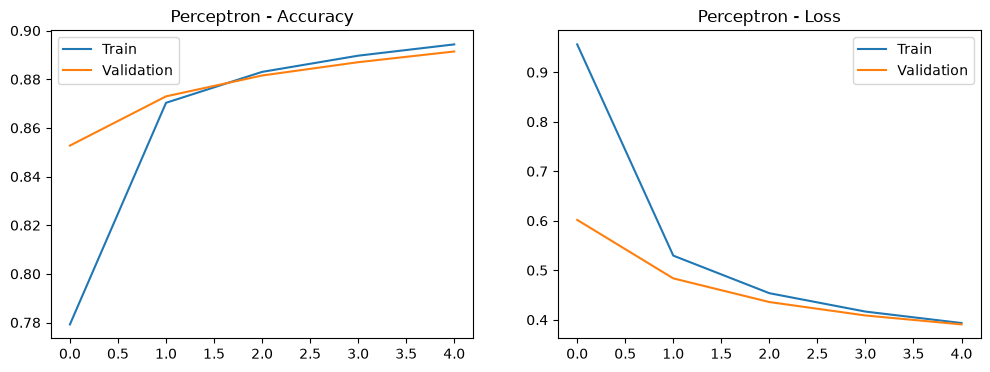

In [75]:
plot_training(history_percp, "Perceptron")

In [76]:
def show_side_by_side(models , model_names , X , X_cnn , y_true , n=5):
    idxs = np.random.choice(len(X), n , replace=False)
    plt.figure(figsize=(15,6))
    for i , idx in enumerate(idxs):
        plt.subplot(2 , n , i+1)
        plt.imshow(X[idx].reshape(28 ,28), cmap="gray")
        plt.axis("off")
        plt.title(f"True: {y_true[idx]}")
        preds=[np.argmax(model.predict(X_cnn[idx].reshape(1,28,28,1) if
        name == "CNN" else X[idx].reshape(1,28,28)))
                  for model , name in zip(models , model_names)]
        plt.subplot(2, n , n+i+1)
        plt.axis("off")
        plt.title("\n".join(f"{n}:{p}" for n,p in zip(model_names , preds)))
    plt.tight_layout()
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step


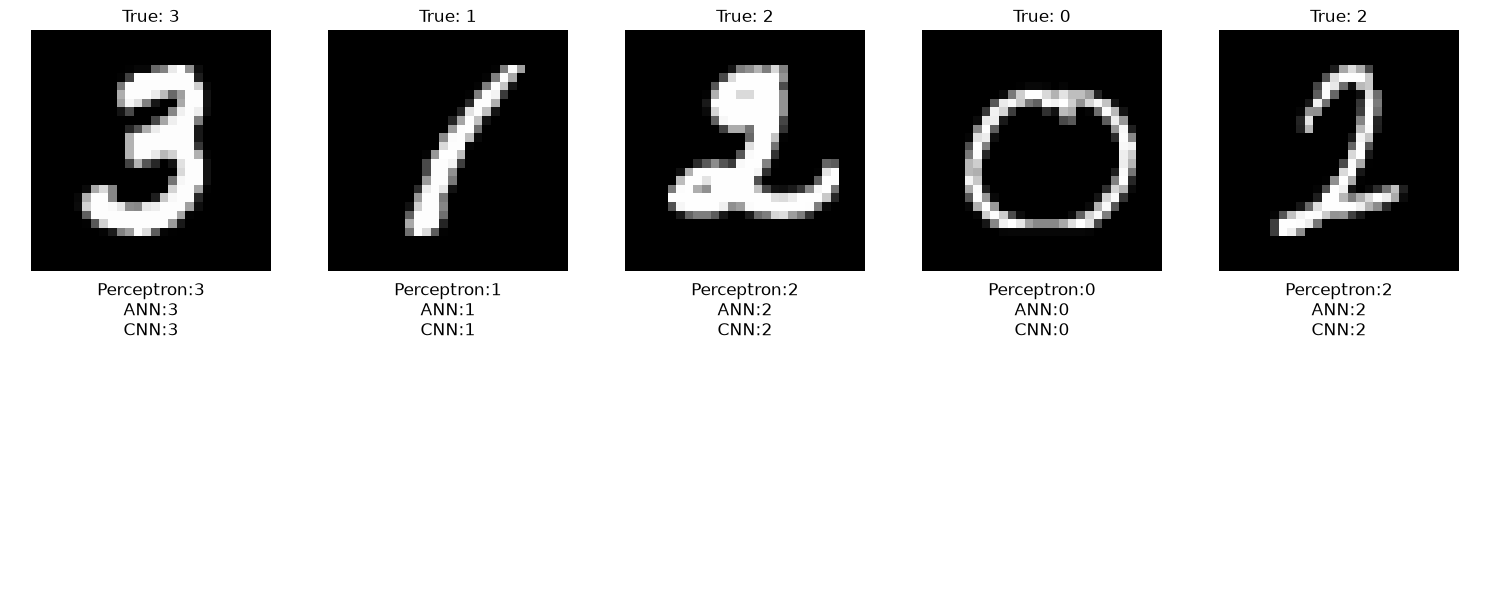

In [81]:
show_side_by_side([perceptron,ann , cnn],["Perceptron","ANN" , "CNN"],
                  X_test_img , X_test_cnn , y_test , 5)

263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


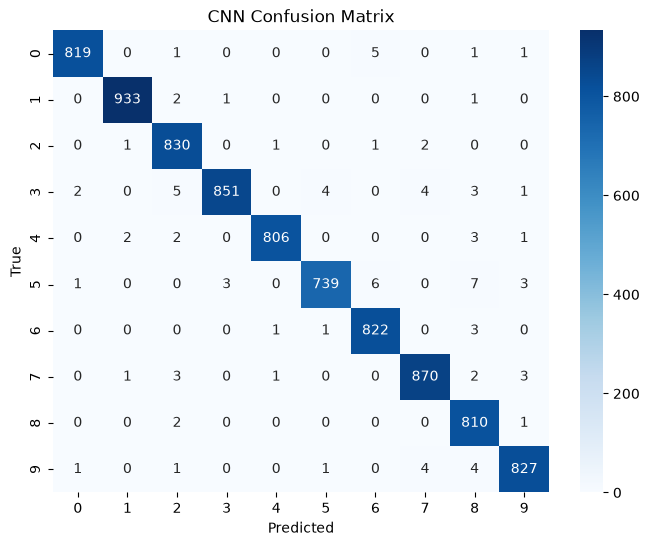

In [84]:
y_pred_cnn = np.argmax(cnn.predict(X_test_cnn),axis=1)
cm = confusion_matrix(y_test , y_pred_cnn)
plt.figure(figsize=(8,6))
sns.heatmap(cm , annot=True , fmt="d" , cmap="Blues")
plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

NameError: name 'pltshow' is not defined

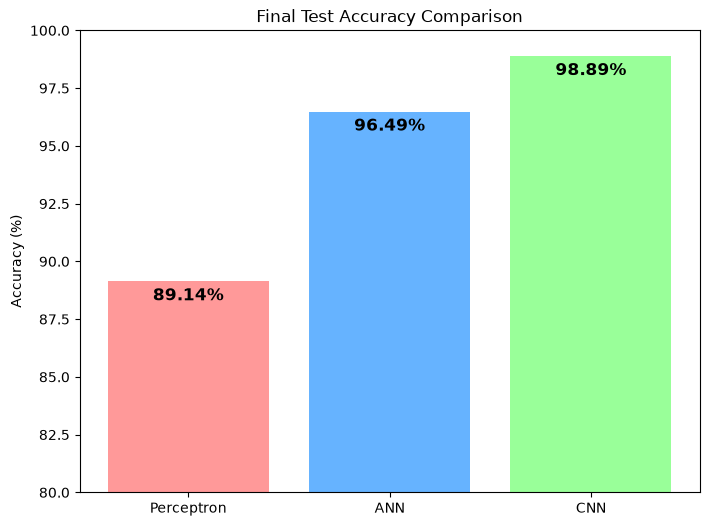

In [85]:
final_accs=[acc_percp*100 , acc_ann*100 , acc_cnn*100]
models=["Perceptron" , "ANN" , "CNN"]

plt.figure(figsize=(8,6))
bars=plt.bar(models , final_accs , color=['#ff9999' , '#66b3ff' , '#99ff99'])
plt.title("Final Test Accuracy Comparison")
plt.ylabel("Accuracy (%)")
for bar , acc in zip(bars , final_accs):
    plt.text(bar.get_x()+bar.get_width()/2 , bar.get_height()-1 , f"{acc:.2f}%",
             ha='center', va='bottom',fontsize=12 , fontweight='bold')
plt.ylim(80,100)
pltshow()

In [87]:
cnn.save("digit_cnn.keras")

In [88]:
loss, accuracy = cnn.evaluate(X_val, y_val, verbose=0)
print(f"Validation accuracy: {accuracy * 100:.2f}%")

NameError: name 'X_val' is not defined

In [89]:

# Save all three trained models
perceptron.save("perceptron.keras")
ann.save("ann.keras")
cnn.save("digit_cnn.keras")

print("All three models saved successfully!")


All three models saved successfully!
